## 6.0


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import networkx as nx
import random
import sys

sys.path.append("../p4")
from fat_tails import mle_alpha, find_x_min

### 6.0.1 BA algorithm

In [2]:
def ba_algorithm(new_edges, max_nodes, init_nodes):
    if new_edges > init_nodes:
        raise ValueError()

    matrix = np.zeros(shape=(max_nodes, max_nodes), dtype=int)
    matrix[:init_nodes, :init_nodes] = 1
    current_nodes = []
    for i in range(init_nodes):
        matrix[i, i] = 0
        current_nodes.extend([i] * (init_nodes - 1))

    for i in range(init_nodes, max_nodes):
        rnd_nodes = set()
        while len(rnd_nodes) < new_edges:
            rnd_nodes.add(random.choice(current_nodes))
        for node in rnd_nodes:
            matrix[i, node] = 1
            matrix[node, i] = 1
            current_nodes.append(node)
            current_nodes.append(i)
    return matrix

In [3]:
new_edges = 2
max_nodes = 10
init_nodes = 3
matrix = ba_algorithm(new_edges, max_nodes, init_nodes)
print(matrix)

[[0 1 1 1 1 1 0 1 1 0]
 [1 0 1 1 0 0 0 0 1 1]
 [1 1 0 0 1 0 1 0 0 1]
 [1 1 0 0 0 1 0 0 0 0]
 [1 0 1 0 0 0 0 1 0 0]
 [1 0 0 1 0 0 1 0 0 0]
 [0 0 1 0 0 1 0 0 0 0]
 [1 0 0 0 1 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]]


### 6.0.2 Animation

In [4]:
new_edges = 1
max_nodes = 20
init_nodes = 3
matrix = ba_algorithm(new_edges, max_nodes, init_nodes)

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))

G_full = nx.from_numpy_array(matrix)
pos = nx.spring_layout(G_full, seed=123)

def update(i):
    ax.clear()

    G_tmp = nx.from_numpy_array(matrix[:i, :i])
    if i == init_nodes:
        node_colors = ["pink"] * i
    else:
        node_colors = ["pink"] * (i - 1) + ["deeppink"]

    nx.draw(
        G_tmp,
        pos,
        ax=ax,
        node_color=node_colors,
        edge_color="lightgray",
    )
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_title(f"t = {i-3}")
    ax.axis("off")


ani = animation.FuncAnimation(
    fig,
    update,
    frames=range(init_nodes, max_nodes + 1),
    interval=700,  # ms between frames
    repeat=False,
)

plt.close(fig)
HTML(ani.to_jshtml())

### 6.0.3 Plot the (averaged) histogram of the degree distribution at time t.

In [6]:
new_edges = 2
max_nodes = 1000
init_nodes = 10
n_runs = 50
times = [20, 100, 500, 1000]  # t = number of nodes in the graph

# hist_sum[j][k] = number of nodes with degree k at time times[j], summed over all runs
hist_sum = np.zeros(shape=(len(times), max_nodes))

for r in range(n_runs):
    matrix = ba_algorithm(new_edges, max_nodes, init_nodes)
    for j in range(len(times)):
        t = times[j]
        degrees = matrix[:t, :t].sum(axis=1)
        hist_sum[j] += np.bincount(degrees, minlength=max_nodes)

# averaged degree distribution P(k): divide by number of runs and number of nodes
p_k = np.zeros(shape=(len(times), max_nodes))
for j in range(len(times)):
    p_k[j] = hist_sum[j] / (n_runs * times[j])

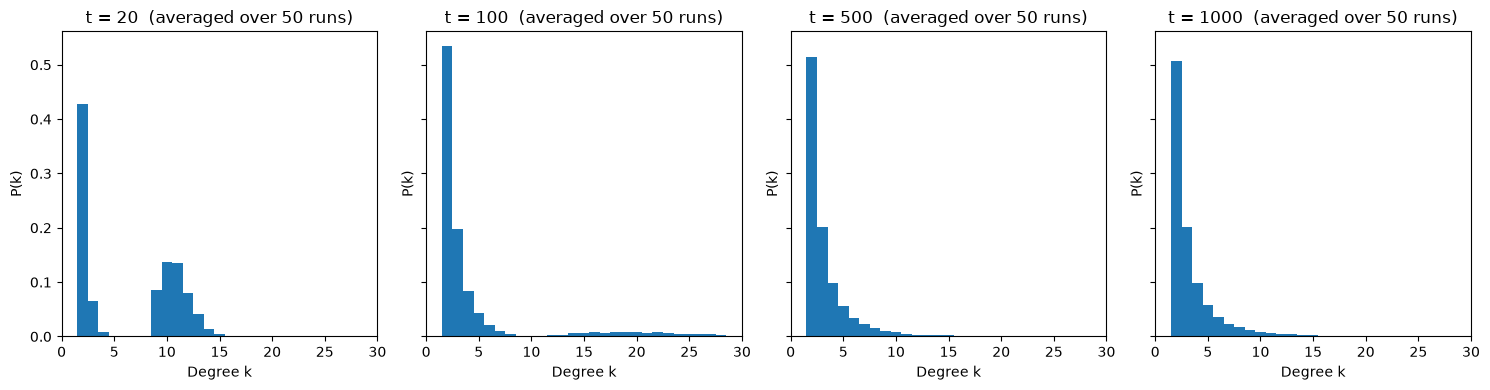

In [7]:
fig, axes = plt.subplots(1, len(times), figsize=(15, 4), sharey=True, sharex=True)
for j in range(len(times)):
    axes[j].bar(range(max_nodes), p_k[j], width=1)
    axes[j].set_xlim(0, 30)
    axes[j].set_xlabel("Degree k")
    axes[j].set_ylabel("P(k)")
    axes[j].set_title(f"t = {times[j]}  (averaged over {n_runs} runs)")
plt.tight_layout()
plt.show()

### 6.0.4 Find the $\alpha$ coefficient for the data from the previous tasks. Does it agree with our theoretical result from the lecture?

for the BA model $P(k) \sim k^{-3}$, so $\alpha = 3$

In [8]:
new_edges = 2
max_nodes = 1000
init_nodes = 10
n_runs = 50

alphas = []
for r in range(n_runs):
    matrix = ba_algorithm(new_edges, max_nodes, init_nodes)
    G = nx.from_numpy_array(matrix)
    x_min, D = find_x_min(G, list(range(2, 30)))
    alphas.append(mle_alpha(G, x_min))

print("mean alpha =", np.mean(alphas), "std =", np.std(alphas))

mean alpha = 3.151474346969102 std = 0.12294685777921739


## 6.3 Check with simulations relation $k_i(t)$ for the original BA model
theoretical expected degree of node $i$ at time $t$: $k_i(t) = m \sqrt{\frac{t}{t_i}}$

/var/folders/sd/tw9ylxjn0xz3rvvmrrsb6y140000gn/T/ipykernel_2394/1970592178.py:17: RuntimeWarning: divide by zero encountered in divide
  y = 3 * np.sqrt(np.array(ns[i]) / x)


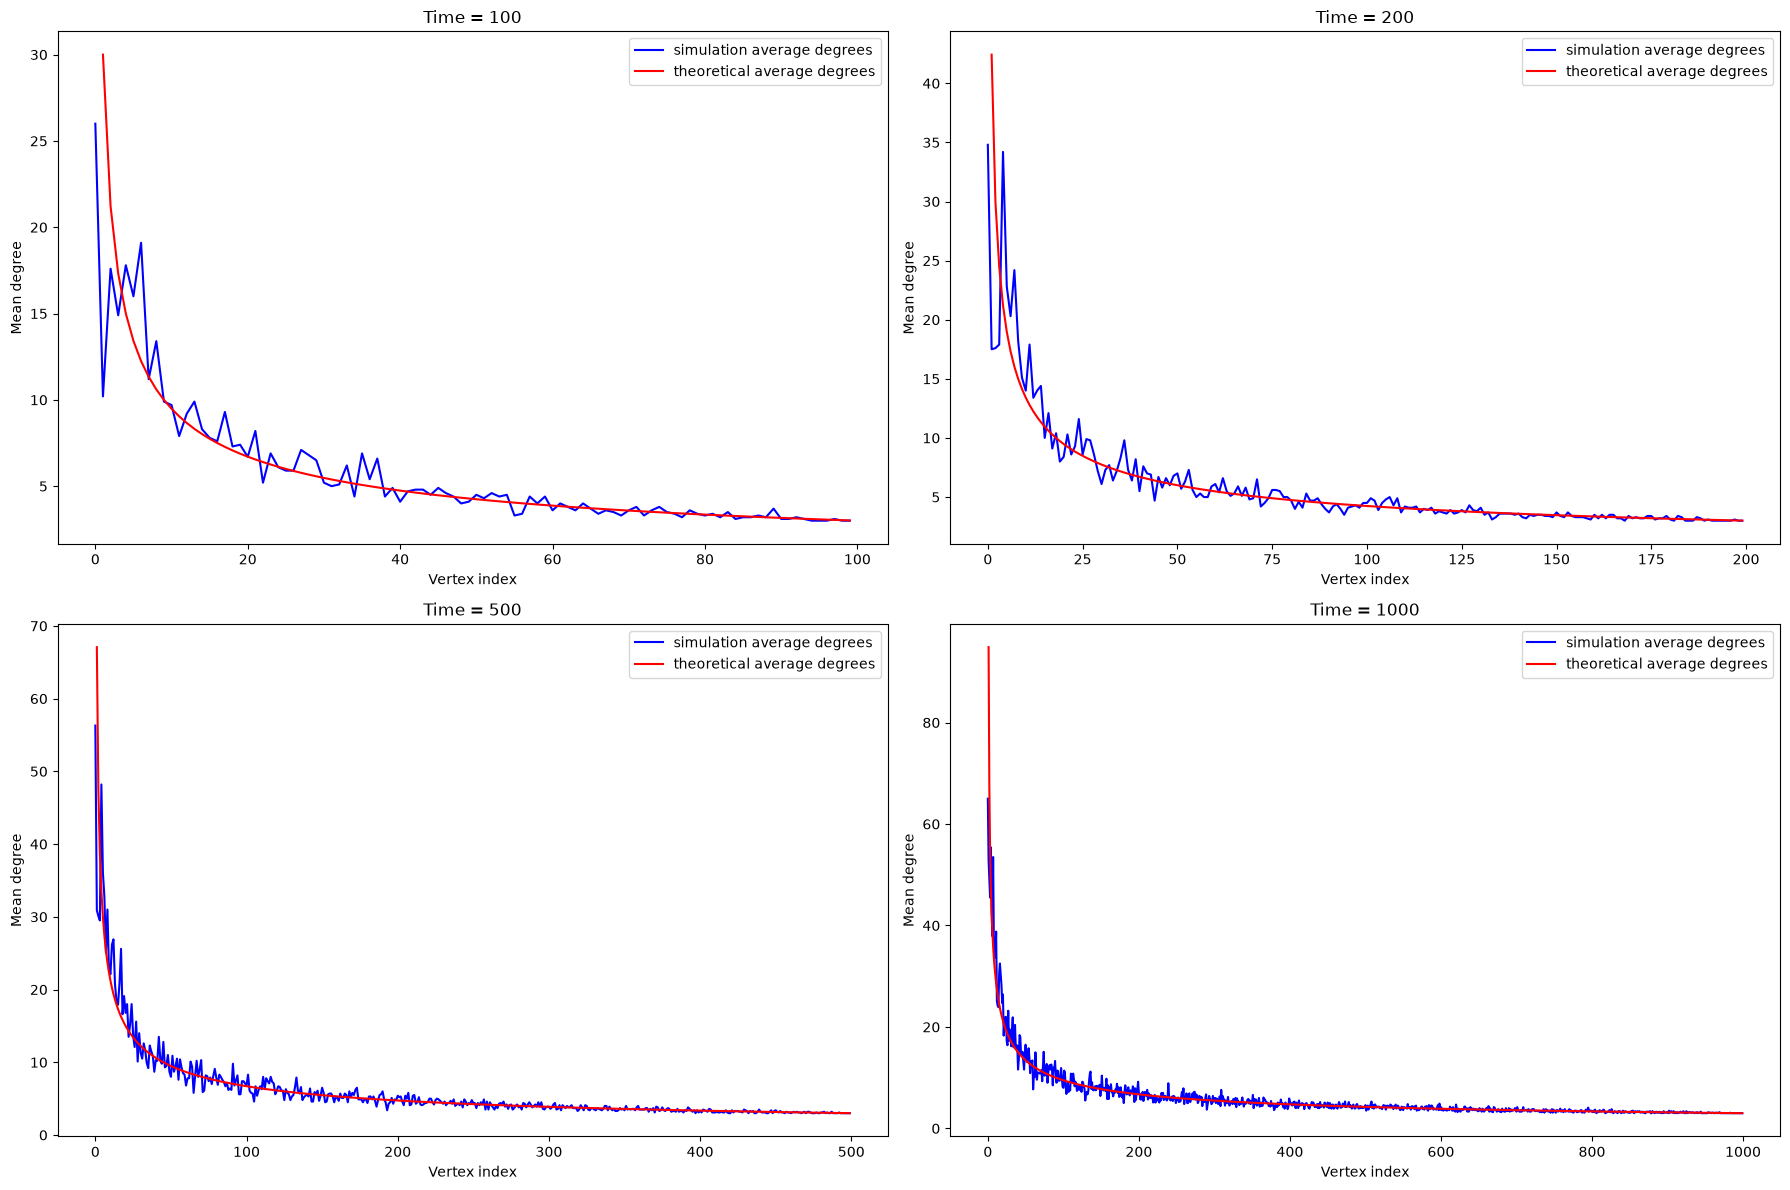

In [9]:
n_runs = 10
ns = [100, 200, 500, 1000]
degree_distributions = [np.zeros(n) for n in ns]
for j,n in enumerate(ns):
    for i in range(n_runs):
        G = nx.barabasi_albert_graph(n, 3)
        degrees = np.array(G.degree())[:, 1]
        degree_distributions[j] += degrees
    degree_distributions[j] /= n_runs

# plot degree distribution
fig = plt.figure(figsize=(18, 12))
for i in range(len(ns)):
    ax = plt.subplot(2, 2, i+1)
    ax.plot(range(ns[i]), degree_distributions[i], c='b', label='simulation average degrees')
    x = np.array(range(ns[i]))
    y = 3 * np.sqrt(np.array(ns[i]) / x)
    ax.plot(x, y, c='r', label='theoretical average degrees')
    ax.set_title("Time = {}".format(ns[i]))
    ax.set_xlabel("Vertex index")
    ax.set_ylabel("Mean degree")
    ax.legend()
plt.tight_layout()
plt.show()

# P6.4 Check with simulations relation ki(t) for model A. [1P]

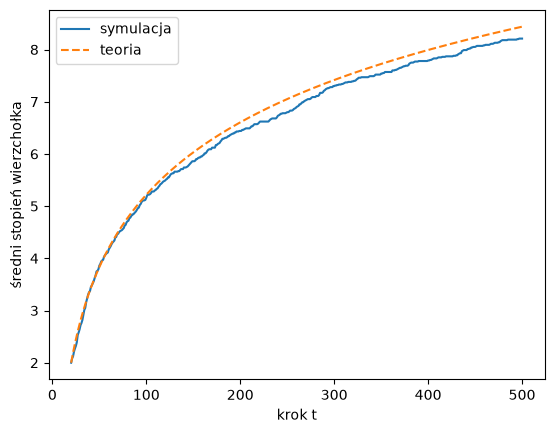

In [13]:
rng = np.random.default_rng(42)
T, runs, m, ti = 500, 100, 2, 20
mean_k = np.zeros(T + 1)

for _ in range(runs):
    degree = np.zeros(T + 2, dtype=int)
    degree[:2] = 1
    for t in range(1, T + 1):
        new = t + 1
        neighbors = rng.choice(new, m, replace=False)
        degree[neighbors] += 1
        degree[new] = m
        if t >= ti:
            mean_k[t] += degree[ti + 1]

t = np.arange(ti, T + 1)
plt.plot(t, mean_k[t] / runs, label="symulacja")
plt.plot(t, m + m * np.log(t / ti), "--", label="teoria")
plt.xlabel("krok t")
plt.ylabel("średni stopień wierzchołka")
plt.legend()
plt.show()

# P6.5 Check with simulations relation ki(t) obtained for model B. [1P]

Theoretical Slope: 0.0200
Measured Slope:    0.0234


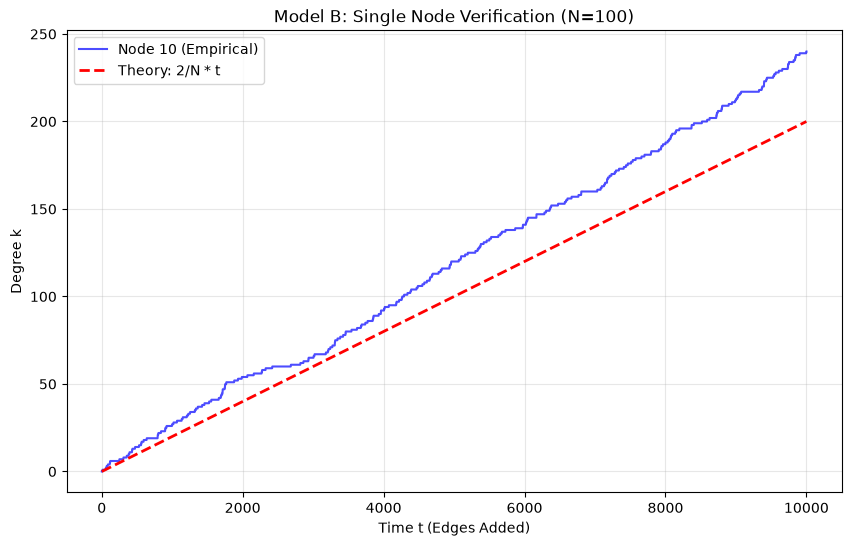

In [11]:
N = 100
T_steps = 10000
node_to_track = 10


G = nx.MultiGraph() 
G.add_nodes_from(range(N))

history = []

u, v = random.sample(range(N), 2)
G.add_edge(u, v)
repeated_nodes = [u, v]

for t in range(T_steps):
    source = random.randint(0, N - 1)
    target = random.choice(repeated_nodes)
    G.add_edge(source, target)
    repeated_nodes.extend([source, target])
    history.append(G.degree(node_to_track))

time_axis = np.arange(1, len(history) + 1)
theoretical_line = (2 / N) * time_axis

plt.figure(figsize=(10, 6))

plt.plot(time_axis, history, color='blue', alpha=0.7, label=f'Node {node_to_track} (Empirical)')

plt.plot(time_axis, theoretical_line, 'r--', linewidth=2, label='Theory: 2/N * t')

plt.title(f"Model B: Single Node Verification (N={N})")
plt.xlabel("Time t (Edges Added)")
plt.ylabel("Degree k")
plt.legend()
plt.grid(True, alpha=0.3)

slope, intercept, _, _, _ = linregress(time_axis, history)
print(f"Theoretical Slope: {2/N:.4f}")
print(f"Measured Slope:    {slope:.4f}")

plt.show()

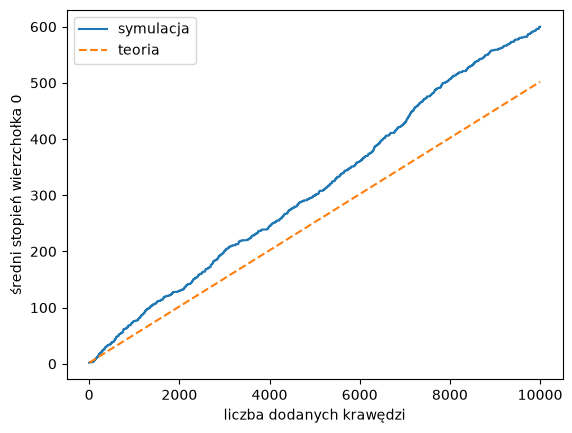

In [17]:
N, T, runs = 40, 10000, 1
mean_k = np.zeros(T + 1)
final = []

for _ in range(runs):
    degree = np.full(N, 2)
    mean_k[0] += degree[0]
    for t in range(1, T + 1):
        u = rng.integers(N)
        weights = degree.copy()
        weights[u] = 0
        v = rng.choice(N, p=weights / weights.sum())
        degree[u] += 1
        degree[v] += 1
        mean_k[t] += degree[0]
    final.extend(degree)

t = np.arange(T + 1)
plt.plot(t, mean_k / runs, label="symulacja")
plt.plot(t, 2 + 2*t/N, "--", label="teoria")
plt.xlabel("liczba dodanych krawędzi")
plt.ylabel("średni stopień wierzchołka 0")
plt.legend()
plt.show()

# P6.6 Find empirically degree distribution for model B. [1P]

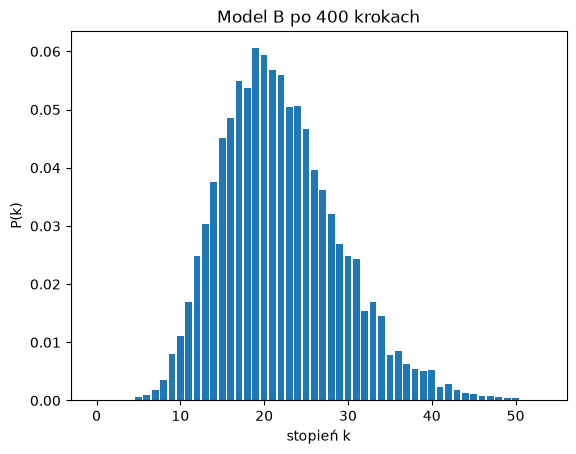

In [15]:
counts = np.bincount(final)
plt.bar(np.arange(len(counts)), counts / len(final))
plt.xlabel("stopień k")
plt.ylabel("P(k)")
plt.title(f"Model B po {T} krokach")
plt.show()